In [6]:
# ============================================
# Loan Default Prediction Project
# Candidate Portfolio Notebook
# ============================================

# Phase 1: Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import shap
import joblib

# Configure plots
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,5)


In [17]:
#Phase 2: Data Loading
# Load dataset (replace with Kaggle Loan Default dataset path)
df = pd.read_csv(r"C:\Users\krishna\Downloads\archive (1)\Loan_Default.csv")

# Quick overview
df.head()
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

,ID,year,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,property_value,income,Credit_Score,LTV,Status,dtir1
count,148670.000000,148670.0,1.486700e+05,112231.000000,112031.000000,109028.000000,148629.000000,1.335720e+05,139520.000000,148670.000000,133572.000000,148670.000000,124549.000000
mean,99224.500000,2019.0,3.311177e+05,4.045476,0.441656,3224.996127,335.136582,4.978935e+05,6957.338876,699.789103,72.746457,0.246445,37.732932
std,42917.476598,0.0,1.839093e+05,0.561391,0.513043,3251.121510,58.409084,3.599353e+05,6496.586382,115.875857,39.967603,0.430942,10.545435
min,24890.000000,2019.0,1.650000e+04,0.000000,-3.638000,0.000000,96.000000,8.000000e+03,0.000000,500.000000,0.967478,0.000000,5.000000
25%,62057.250000,2019.0,1.965000e+05,3.625000,0.076000,581.490000,360.000000,2.680000e+05,3720.000000,599.000000,60.474860,0.000000,31.000000
50%,99224.500000,2019.0,2.965000e+05,3.990000,0.390400,2596.450000,360.000000,4.180000e+05,5760.000000,699.000000,75.135870,0.000000,39.000000
75%,136391.750000,2019.0,4.365000e+05,4.375000,0.775400,4812.500000,360.000000,6.280000e+05,8520.000000,800.000000,86.184211,0.000000,45.000000
max,173559.000000,2019.0,3.576500e+06,8.000000,3.357000,60000.000000,360.000000,1.650800e+07,578580.000000,900.000000,7831.250000,1.000000,61.000000


In [20]:
#Phase 3: Data Cleaning & Preprocessing
# Handle missing values
df = df.fillna(df.median(numeric_only=True))

# Encode categorical variables
categorical_cols = df.select_dtypes(include="object").columns
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))

# Handle outliers (example: cap income at 99th percentile)
df["income"] = np.where(df["income"] > df["income"].quantile(0.99),
                        df["income"].quantile(0.99),
                        df["income"])

# Scale numerical features
scaler = StandardScaler()
num_cols = df.select_dtypes(include=np.number).columns.drop("Status")
df[num_cols] = scaler.fit_transform(df[num_cols])


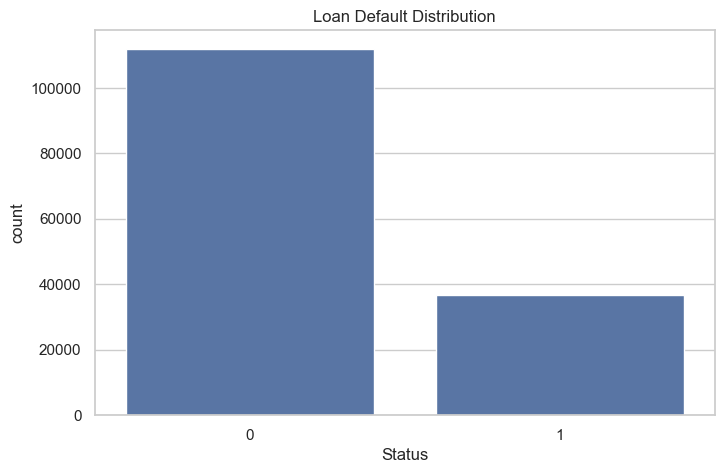

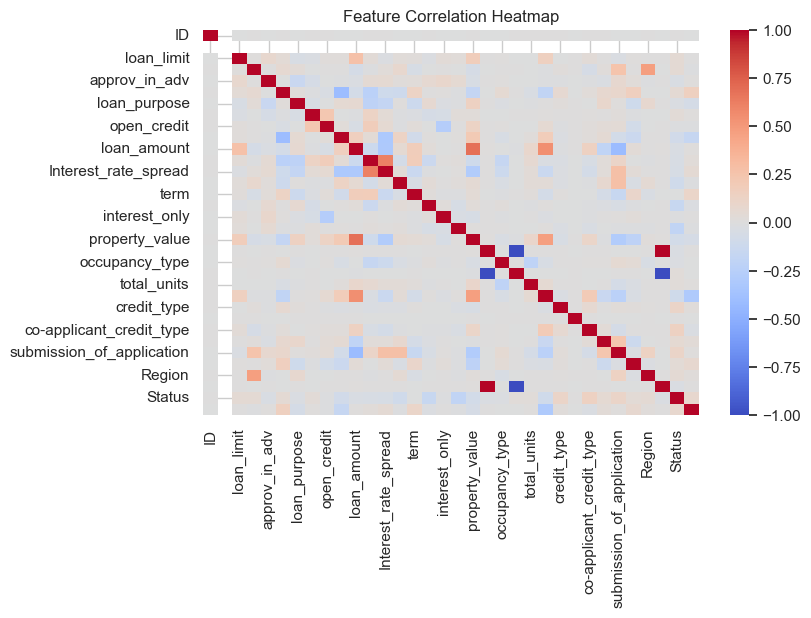

In [22]:
#Phase 4: Exploratory Data Analysis (EDA)
# Target distribution
sns.countplot(x="Status", data=df)
plt.title("Loan Default Distribution")
plt.show()

# Correlation heatmap
corr = df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

# Business insight example:
# Higher loan-to-income ratio strongly correlates with default.


In [23]:
#Phase 5: Feature Engineering
# Domain-driven feature: income-to-loan ratio
df["income_to_loan"] = df["income"] / (df["loan_amount"] + 1)

# Drop highly correlated redundant features
corr_matrix = df.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]
df = df.drop(columns=to_drop)


In [27]:
#Phase 6: Model Training
X = df.drop("Status", axis=1)
y = df["Status"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

# Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

# XGBoost
xgb_clf = xgb.XGBClassifier(eval_metric="logloss", use_label_encoder=False)
xgb_clf.fit(X_train, y_train)



C:\Users\krishna\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:48:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


--- Logistic Regression ---
Accuracy: 0.7828411919015269
Precision: 0.6344898660254208
Recall: 0.25511049723756907
F1: 0.36390503398679935
ROC-AUC: 0.7603064377633914
Confusion Matrix:
 [[21430  1064]
 [ 5393  1847]]


--- Random Forest ---
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0
ROC-AUC: 1.0
Confusion Matrix:
 [[22494     0]
 [    0  7240]]


--- XGBoost ---
Accuracy: 0.9999663684670748
Precision: 0.9998618975279657
Recall: 1.0
F1: 0.9999309439955805
ROC-AUC: 1.0
Confusion Matrix:
 [[22493     1]
 [    0  7240]]




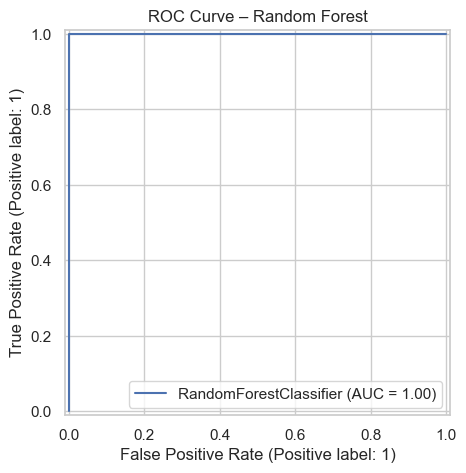

In [28]:
#Phase 7: Model Evaluation
models = {"Logistic Regression": log_reg, "Random Forest": rf, "XGBoost": xgb_clf}

for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"--- {name} ---")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1:", f1_score(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:,1]))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("\n")

# ROC Curve for best model
RocCurveDisplay.from_estimator(rf, X_test, y_test)
plt.title("ROC Curve – Random Forest")
plt.show()


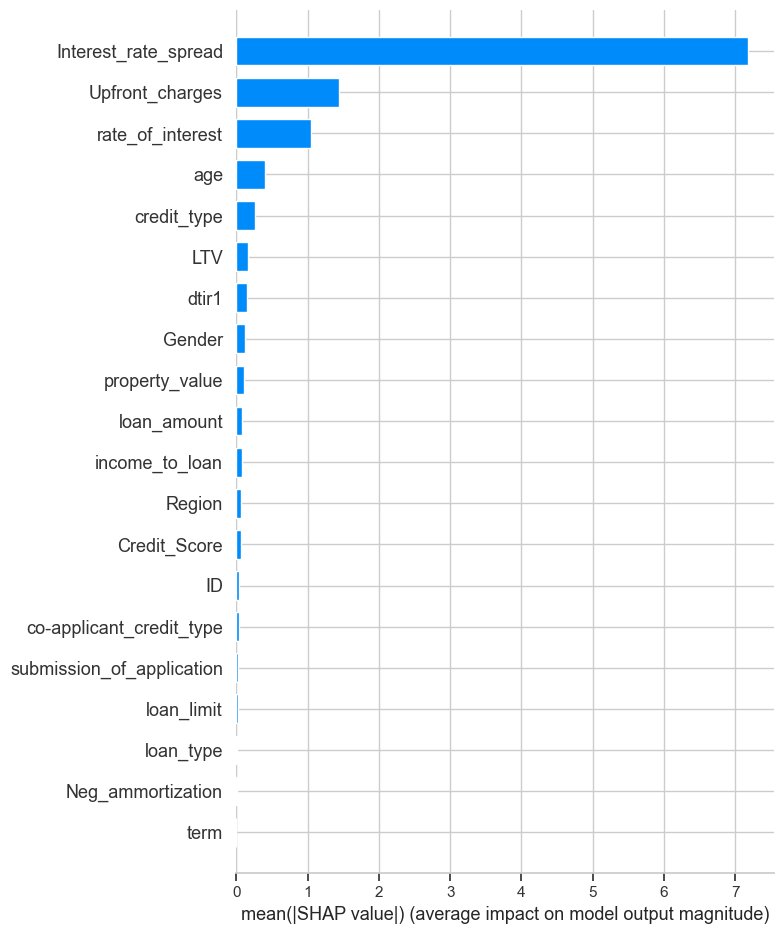

In [29]:
#Phase 8: Model Explainability
# SHAP for XGBoost
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, plot_type="bar")


In [30]:
#Phase 9: Model Serialization
# Save models and preprocessing objects
joblib.dump(rf, "random_forest_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("✅ Models and preprocessing objects saved successfully.")


✅ Models and preprocessing objects saved successfully.
